In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel(r'C:\Users\User\Desktop\Артур\Artur\Moneyball_Салават_Юлаев.xlsx', sheet_name='Статистика')

In [29]:
df.head()

,Имя игрока,Позиция,Игры,Гол,Пас,Очки,Плюс/минус,Штраф,Ср. время на льду,Время в минутах,Зарплата,Стоимость очка,Стоимость минуты (руб.)
0,Стюарт,З,63,1,21,22,-3,36,17:29:00,1049,30,-,28598.665400
1,Цулыгин,З,75,4,11,15,-12,30,16:57:00,1017,4,-,3933.136676
2,Кулик,З,61,2,12,14,3,20,14:31:00,871,12,-,13777.267510
3,Зоркин,З,60,5,6,11,5,22,17:18:00,1038,24,-,23121.387280
4,Панин,З,77,4,7,11,11,56,16:08:00,968,10,-,10330.578510


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Имя игрока               18 non-null     str    
 1   Позиция                  18 non-null     str    
 2   Игры                     18 non-null     int64  
 3   Гол                      18 non-null     int64  
 4   Пас                      18 non-null     int64  
 5   Очки                     18 non-null     int64  
 6   Плюс/минус               18 non-null     int64  
 7   Штраф                    18 non-null     int64  
 8   Ср. время на льду        18 non-null     object 
 9   Время в минутах          18 non-null     int64  
 10  Зарплата                 18 non-null     int64  
 11  Стоимость очка           18 non-null     object 
 12  Стоимость минуты (руб.)  18 non-null     float64
dtypes: float64(1), int64(8), object(2), str(2)
memory usage: 2.0+ KB


In [31]:
df.describe().round(2)

,Игры,Гол,Пас,Очки,Плюс/минус,Штраф,Время в минутах,Зарплата,Стоимость минуты (руб.)
count,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00
mean,62.72,9.44,15.00,24.44,0.28,28.28,969.22,22.94,22229.46
std,13.71,6.78,8.68,14.15,8.46,17.02,131.44,22.84,18689.39
min,26.00,1.00,4.00,7.00,-19.00,8.00,731.00,3.00,3933.14
25%,60.00,4.00,8.00,12.50,-2.25,17.25,879.25,7.00,7471.33
50%,65.50,7.50,14.00,22.00,2.00,25.50,955.50,17.50,18606.37
75%,72.50,15.50,19.25,34.50,5.00,35.00,1044.00,30.00,28380.17
max,77.00,22.00,36.00,54.00,11.00,73.00,1291.00,100.00,77459.33


In [32]:
df['Стоимость очка'] = pd.to_numeric(df['Стоимость очка'], errors = 'coerce')
df_clean = df.dropna(subset = ['Стоимость очка'])
print(df_clean)

     Имя игрока Позиция  Игры  Гол  Пас  Очки  Плюс/минус  Штраф  \
7        Ремпал       Н    48   18   36    54           4     44   
8       Родуолд       Н    77   22   26    48         -19     29   
9     Жаровский       Н    69   16   28    44           1     40   
10       Броссо       Н    61   20   16    36           2     73   
11       Сучков       Н    76   16   20    36           1     30   
12  Кузнецов М.       Н    71   13   17    30           6     18   
13      Ефремов       Н    71   14   12    26           0     32   
14  Кузнецов Е.       Н    26    7   13    20           5     17   
15     Алалыкин       Н    51    8   15    23          -6     10   
16      Горшков       Н    73    7   15    22           9      8   
17           Ян       Н    42    8    4    12         -15     14   

   Ср. время на льду  Время в минутах  Зарплата  Стоимость очка  \
7           21:31:00             1291       100        1.851852   
8           18:58:00             1138        30  

In [33]:
df_clean ['Эффективность'] = df_clean['Очки'] / df_clean['Зарплата']
df_clean.sort_values('Эффективность',ascending=False)

,Имя игрока,Позиция,Игры,Гол,Пас,Очки,Плюс/минус,Штраф,Ср. время на льду,Время в минутах,Зарплата,Стоимость очка,Стоимость минуты (руб.),Эффективность
9,Жаровский,Н,69,16,28,44,1,40,15:04:00,904,5,0.113636,5530.973451,8.800000
16,Горшков,Н,73,7,15,22,9,8,12:11:00,731,3,0.136364,4103.967168,7.333333
12,Кузнецов М.,Н,71,13,17,30,6,18,13:15:00,795,5,0.166667,6289.308176,6.000000
11,Сучков,Н,76,16,20,36,1,30,15:17:00,917,15,0.416667,16357.688110,2.400000
14,Кузнецов Е.,Н,26,7,13,20,5,17,18:16:00,1096,10,0.500000,9124.087591,2.000000
8,Родуолд,Н,77,22,26,48,-19,29,18:58:00,1138,30,0.625000,26362.038660,1.600000
10,Броссо,Н,61,20,16,36,2,73,17:26:00,1046,29,0.805556,27724.665390,1.241379
15,Алалыкин,Н,51,8,15,23,-6,10,15:59:00,959,20,0.869565,20855.057350,1.150000
13,Ефремов,Н,71,14,12,26,0,32,15:43:00,943,35,1.346154,37115.588550,0.742857
7,Ремпал,Н,48,18,36,54,4,44,21:31:00,1291,100,1.851852,77459.333850,0.540000


In [34]:
print(df_clean['Зарплата'])

7     100
8      30
9       5
10     29
11     15
12      5
13     35
14     10
15     20
16      3
17     35
Name: Зарплата, dtype: int64


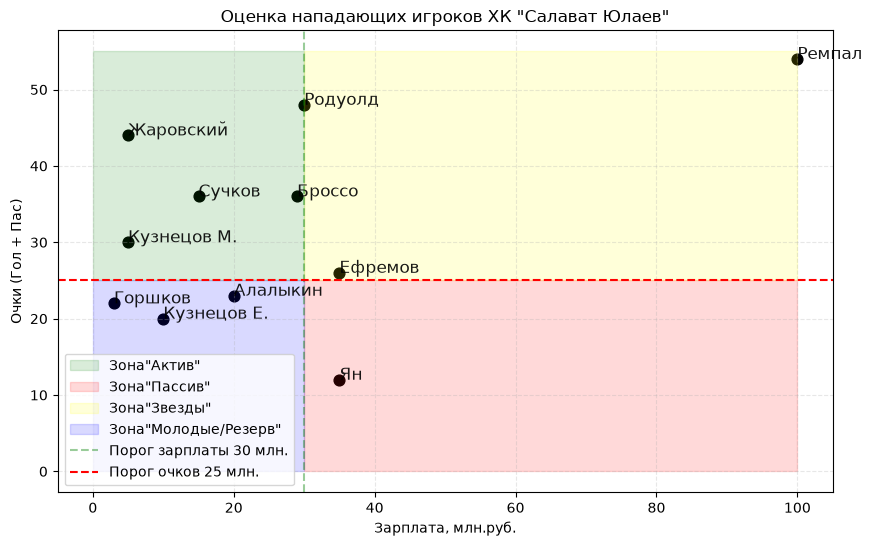

In [35]:
plt.figure(figsize=(10, 6)) #создает фигуру где будет график
plt.scatter(df_clean['Зарплата'],df_clean['Очки'], color='black', s=60) #риcует точки (х,у,цвет, размер)
plt.title('Оценка нападающих игроков ХК "Салават Юлаев"',loc='center')
plt.xlabel('Зарплата, млн.руб.')
plt.ylabel('Очки (Гол + Пас)')
plt.grid(True, linestyle='--', alpha=0.3) #строит сетку
plt.gca().add_patch(plt.Rectangle((0,25), 30, 30, color='green', alpha=0.15,label='Зона"Актив"'))
plt.gca().add_patch(plt.Rectangle((30,0), 70, 25, color='red', alpha=0.15,label='Зона"Пассив"'))
plt.gca().add_patch(plt.Rectangle((30,25), 70, 30, color='yellow', alpha=0.15,label='Зона"Звезды"'))
plt.gca().add_patch(plt.Rectangle((0,0), 30, 25, color='blue', alpha=0.15,label='Зона"Молодые/Резерв"'))
for index, row in df_clean.iterrows():   
    plt.text(row['Зарплата'], row['Очки'], row['Имя игрока'], fontsize=12, alpha=0.9)
plt.axvline(x=30, color='green',linestyle='--', label='Порог зарплаты 30 млн.',alpha=0.4)
plt.axhline(y=25,color='red',linestyle='--',label='Порог очков 25 млн.')
plt.legend(loc='best')
plt.show() #вывод 

## __Анализ эффективности контрактов нападающих ХК "Салават Юлаев"__

На основании построенной матрицы «Зарплата — Очки» игроки распределены по четырем стратегическим зонам:

- Зона «Актив» (МАЛО ДЕНЕГ - МНОГО ОЧКОВ): 
        Игроки, демонстрирующие высокую результативность при умеренной стоимости контракта (зарплата ≤ 30 млн руб., очки ≥ 25). Сюда входят Жаровский, Сучков и Кузнецов М. Также можно отметить и Родуолда и Броссо - получают больше, находятся на границы с "Звезды". Это наиболее эффективные контракты команды, обеспечивающие максимальную отдачу на вложенный рубль.
>> Родуолд, Броссо - между зонами "Актив" и "Звезды" - скорее всего будут просить прибавку в зарплате по завершению контракта.
- Зона «Звезды» (МНОГО ДЕНЕГ - МНОГО ОЧКОВ): 
        Ремпал (100 млн руб., 54 очка). Ремпал - главная звезда команды. Игрок с максимальной результативностью в команде (54 очка), оправдывает высокую зарплату результатом, который приносит на льду. Является ключевым игроком для достижения турнирных целей.
- Зона «Молодые/резерв» (МАЛО ДЕНЕГ - МАЛО ОЧКОВ): 
           Горшков, Алалыкин, Кузнецов. Наигрывать в матчах, давать возможности получать игровую практику в КХЛ. Присмотреться к игрокам, которые несколько лет подряд не прогрессируют и не выходят из этой зоны. Молодежь способная заменить игроков на травме, либо же для ротации состава  
- Зона «Пассив»(МНОГО ДЕНЕГ - МАЛО ОЧКОВ): 
        Игрок Ян (35 млн руб., 12 очков). Находится в зоне неэффективных трат. При высокой стоимости контракта результативность значительно ниже целевого порога. Рекомендуется пересмотр условий контракта или изменение игровой роли.
>> Ян - стоит пересмотреть условия контракта или же запрашивать расторжение/обмен. 

> Итоговый вывод: Бюджетная политика ХК "Салават Юлаев" признана эффективной, текущий состав имеет хороший баланс. В зоне "Пассив" находится один игрок. Требуется корректировка по игроку из зоны «Пассив».